# 01 — Exploração dos dados

**Tema 4: inadimplência de cartão de crédito (classificação binária)**. O objetivo é prever se o cliente ficará inadimplente no mês seguinte usando informações demográficas, limite de crédito, histórico de pagamento e valores de faturas e pagamentos. A tarefa é relevante para estimar risco de crédito; a base é histórica e não deve ser tomada como representativa da população atual.

**Fonte:** Yeh, I.-C. (2009). [Default of Credit Card Clients, UCI Machine Learning Repository](https://doi.org/10.24432/C55S3H), [ficha e download oficial](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Os registros de pagamento referem-se a abril–setembro de 2005 em Taiwan; o alvo se refere ao mês seguinte. O arquivo Excel original é preservado, e o cabeçalho útil é a segunda linha.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

raiz = Path.cwd() if Path("data").is_dir() else Path.cwd().parent
pasta_figuras = raiz / "figures"
pasta_figuras.mkdir(exist_ok=True)
base = pd.read_excel(raiz / "data" / "default_credit_card_clients.xls", header=1)

alvo = "default payment next month"
preditores = base.drop(columns=["ID", alvo])
status_pagamento = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

display(pd.Series({
    "Instâncias": len(base),
    "Colunas no arquivo": base.shape[1],
    "Atributos preditores": preditores.shape[1],
    "Identificadores distintos": base["ID"].nunique(),
    "Classes": base[alvo].nunique(),
}, name="Quantidade").to_frame())

,Quantidade
Instâncias,30000
Colunas no arquivo,25
Atributos preditores,23
Identificadores distintos,30000
Classes,2


## Dicionário de atributos

A tabela distingue o tipo semântico do tipo de armazenamento. **ID** identifica a linha e não será usado como preditor. O alvo **default payment next month** usa 0 = sem inadimplência e 1 = com inadimplência no mês seguinte. A planilha usa `PAY_0` para setembro; não existe uma coluna `PAY_1`.

In [2]:
descricao = {
    "ID": ("Identificador", "Identificador do cliente no arquivo; excluído dos modelos."),
    "LIMIT_BAL": ("Numérico", "Limite de crédito concedido (NT$)."),
    "SEX": ("Categórico nominal", "Sexo no cadastro: 1 = masculino, 2 = feminino."),
    "EDUCATION": ("Categórico", "Escolaridade: 1 = pós-graduação, 2 = universidade, 3 = ensino médio, 4 = outros."),
    "MARRIAGE": ("Categórico nominal", "Estado civil: 1 = casado, 2 = solteiro, 3 = outros."),
    "AGE": ("Numérico discreto", "Idade em anos."),
    alvo: ("Classe binária", "Inadimplência no mês seguinte: 0 = não, 1 = sim."),
}
meses = ["setembro", "agosto", "julho", "junho", "maio", "abril"]
for i, (col, mes) in enumerate(zip(status_pagamento, meses), 1):
    descricao[col] = (
        "Categórico (atrasos ordenados)",
        f"Status em {mes}/2005: −1 = em dia; 1–8 = meses de atraso; 9 = ≥ 9 meses.",
    )
    descricao[f"BILL_AMT{i}"] = ("Numérico", f"Valor da fatura de {mes}/2005 (NT$).")
    descricao[f"PAY_AMT{i}"] = ("Numérico", f"Valor pago em {mes}/2005 (NT$).")

dicionario = pd.DataFrame.from_dict(descricao, orient="index", columns=["Tipo semântico", "Significado"])
dicionario.insert(0, "Tipo na planilha lida", base.dtypes.astype(str))
display(dicionario.loc[base.columns])

,Tipo na planilha lida,Tipo semântico,Significado
ID,int64,Identificador,Identificador do cliente no arquivo; excluído ...
LIMIT_BAL,int64,Numérico,Limite de crédito concedido (NT$).
SEX,int64,Categórico nominal,"Sexo no cadastro: 1 = masculino, 2 = feminino."
EDUCATION,int64,Categórico,"Escolaridade: 1 = pós-graduação, 2 = universid..."
MARRIAGE,int64,Categórico nominal,"Estado civil: 1 = casado, 2 = solteiro, 3 = ou..."
AGE,int64,Numérico discreto,Idade em anos.
PAY_0,int64,Categórico (atrasos ordenados),Status em setembro/2005: −1 = em dia; 1–8 = me...
PAY_2,int64,Categórico (atrasos ordenados),Status em agosto/2005: −1 = em dia; 1–8 = mese...
PAY_3,int64,Categórico (atrasos ordenados),Status em julho/2005: −1 = em dia; 1–8 = meses...
PAY_4,int64,Categórico (atrasos ordenados),Status em junho/2005: −1 = em dia; 1–8 = meses...


## Distribuição do alvo

,Quantidade,% da base
default payment next month,,
0 — Sem inadimplência,23364,77.88
1 — Com inadimplência,6636,22.12


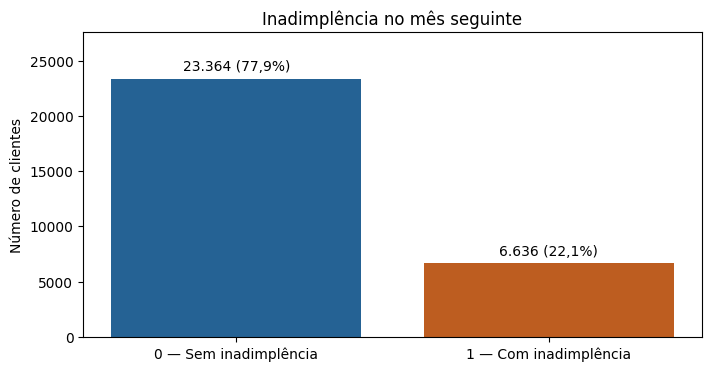

In [3]:
contagens = base[alvo].value_counts().sort_index()
classes = contagens.index.map({0: "0 — Sem inadimplência", 1: "1 — Com inadimplência"})
distribuicao = pd.DataFrame({
    "Quantidade": contagens.to_numpy(),
    "% da base": contagens.to_numpy() / len(base) * 100,
}, index=classes)
display(distribuicao.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
barras = ax.bar(classes, contagens, color=["#256294", "#bd5d20"])
ax.bar_label(barras, labels=[
    f"{n:,}".replace(",", ".") + f" ({p:.1f}%)".replace(".", ",")
    for n, p in zip(contagens, distribuicao["% da base"])
], padding=4)
ax.set(title="Inadimplência no mês seguinte", ylabel="Número de clientes", ylim=(0, contagens.max() * 1.18))
fig.savefig(pasta_figuras / "eda_classes.png", dpi=150)
plt.show()

## Qualidade dos dados

Os códigos fora da documentação não são células vazias e não são tratados automaticamente como erros. Para registros repetidos, distinguimos linhas completas, linhas iguais sem ID e linhas com os mesmos preditores, independentemente do alvo.

In [4]:
ausentes = base.isna().sum().rename("Ausentes").to_frame()
display(ausentes.T)

repetidos = preditores.duplicated(keep=False)
grupos_repetidos = base.loc[repetidos, preditores.columns.tolist() + [alvo]].groupby(
    preditores.columns.tolist(), dropna=False
)[alvo].nunique()
display(pd.Series({
    "Células ausentes": ausentes["Ausentes"].sum(),
    "IDs repetidos além da primeira ocorrência": base["ID"].duplicated().sum(),
    "Linhas completas repetidas além da primeira ocorrência": base.duplicated().sum(),
    "Linhas repetidas sem ID, mantendo o alvo": base.drop(columns="ID").duplicated().sum(),
    "Linhas repetidas apenas nos preditores, além da primeira ocorrência": preditores.duplicated().sum(),
    "Registros em grupos de preditores repetidos (inclui a primeira ocorrência)": repetidos.sum(),
    "Grupos de preditores idênticos": len(grupos_repetidos),
    "Grupos de preditores idênticos com alvos diferentes": grupos_repetidos.gt(1).sum(),
}, name="Quantidade").to_frame())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
Ausentes,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,Quantidade
Células ausentes,0
IDs repetidos além da primeira ocorrência,0
Linhas completas repetidas além da primeira ocorrência,0
"Linhas repetidas sem ID, mantendo o alvo",35
"Linhas repetidas apenas nos preditores, além da primeira ocorrência",56
Registros em grupos de preditores repetidos (inclui a primeira ocorrência),108
Grupos de preditores idênticos,52
Grupos de preditores idênticos com alvos diferentes,21


In [5]:
dominios = {
    "SEX": {1, 2},
    "EDUCATION": {1, 2, 3, 4},
    "MARRIAGE": {1, 2, 3},
    **{col: {-1, *range(1, 10)} for col in status_pagamento},
    alvo: {0, 1},
}
fora_do_dominio = []
for col, codigos_documentados in dominios.items():
    contagem = base[col].value_counts().sort_index()
    for valor, n in contagem.items():
        if valor not in codigos_documentados:
            fora_do_dominio.append((col, valor, n, n / len(base) * 100))
display(pd.DataFrame(
    fora_do_dominio, columns=["Atributo", "Código não documentado", "Ocorrências", "% do atributo"]
).round(2))

monetarios = ["LIMIT_BAL", *base.filter(regex=r"^(BILL_AMT|PAY_AMT)\d+$").columns]
resumo = base[["AGE", *monetarios]].describe(percentiles=[0.25, 0.5, 0.75]).T
resumo["Zeros"] = base[resumo.index].eq(0).sum()
resumo["Negativos"] = base[resumo.index].lt(0).sum()
display(resumo.round(2))

,Atributo,Código não documentado,Ocorrências,% do atributo
0,EDUCATION,0,14,0.05
1,EDUCATION,5,280,0.93
2,EDUCATION,6,51,0.17
3,MARRIAGE,0,54,0.18
4,PAY_0,-2,2759,9.20
5,PAY_0,0,14737,49.12
6,PAY_2,-2,3782,12.61
7,PAY_2,0,15730,52.43
8,PAY_3,-2,4085,13.62
9,PAY_3,0,15764,52.55


,count,mean,std,min,25%,50%,75%,max,Zeros,Negativos
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0,0,0
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,0,0
BILL_AMT1,30000.0,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.00,964511.0,2008,590
BILL_AMT2,30000.0,49179.08,71173.77,-69777.0,2984.75,21200.0,64006.25,983931.0,2506,669
BILL_AMT3,30000.0,47013.15,69349.39,-157264.0,2666.25,20088.5,60164.75,1664089.0,2870,655
BILL_AMT4,30000.0,43262.95,64332.86,-170000.0,2326.75,19052.0,54506.00,891586.0,3195,675
BILL_AMT5,30000.0,40311.40,60797.16,-81334.0,1763.00,18104.5,50190.50,927171.0,3506,655
BILL_AMT6,30000.0,38871.76,59554.11,-339603.0,1256.00,17071.0,49198.25,961664.0,4020,688
PAY_AMT1,30000.0,5663.58,16563.28,0.0,1000.00,2100.0,5006.00,873552.0,5249,0
PAY_AMT2,30000.0,5921.16,23040.87,0.0,833.00,2009.0,5000.00,1684259.0,5396,0


A UCI documenta `EDUCATION` 1–4, `MARRIAGE` 1–3 e os status de pagamento −1 e 1–9. A planilha também contém `EDUCATION` 0/5/6, `MARRIAGE` 0 e `PAY_*` −2/0; não atribuímos significado a esses códigos. Também verificamos valores monetários negativos separadamente, sem supor que sejam inválidos. O resumo numérico, o gráfico da classe e as distribuições abaixo complementam a inspeção de qualidade.

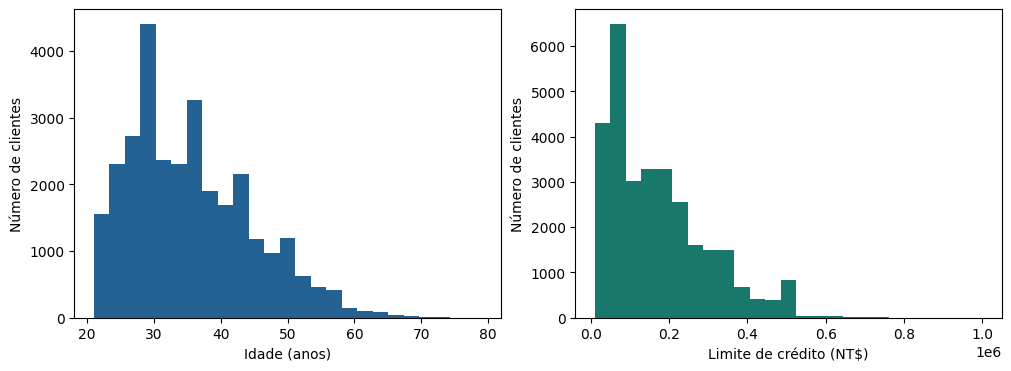

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for col, nome, cor, ax in [
    ("AGE", "Idade (anos)", "#256294", axes[0]),
    ("LIMIT_BAL", "Limite de crédito (NT$)", "#18786b", axes[1]),
]:
    ax.hist(base[col], bins=25, color=cor)
    ax.set(xlabel=nome, ylabel="Número de clientes")
fig.savefig(pasta_figuras / "eda_idade_limite.png", dpi=150)
plt.show()

**TODO (grupo):** interpretar os gráficos e as ocorrências de qualidade de dados; discutir o contexto e as limitações da base.